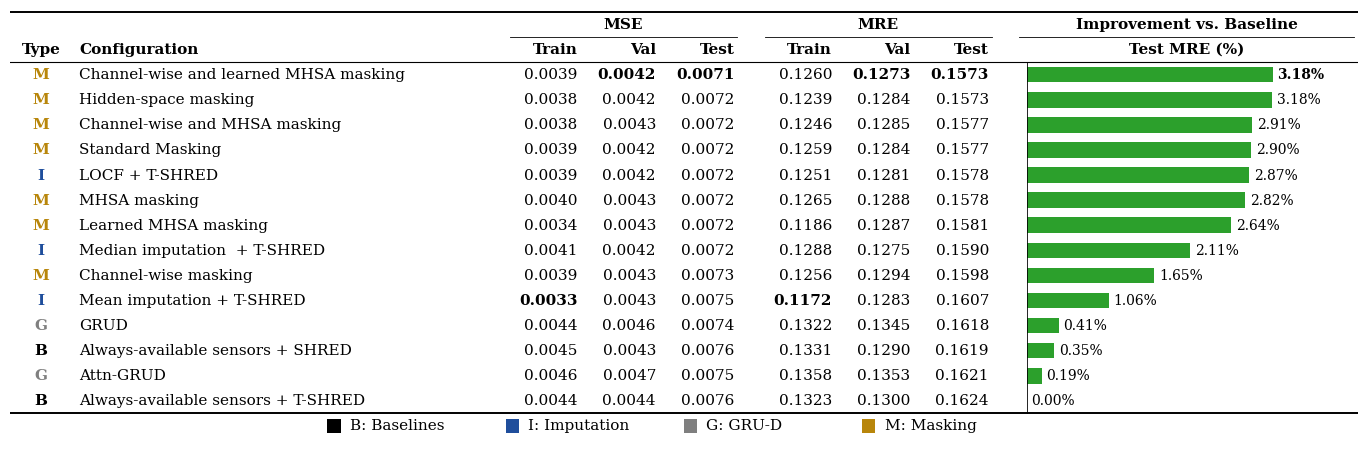

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
})

path = "results_df/notebook4/dataframe_errors.csv"
df = pd.read_csv(path).sort_values("test-mre").reset_index(drop=True)

num_cols = ["train-mse", "val-mse", "test-mse", "train-mre", "val-mre", "test-mre"]
best = df[num_cols].min()

# ---- improvement vs baseline (T.0 nel CSV, mostrato come B) ----
BASELINE_PREFIX = "(T.0)"
base_mre = df.loc[df["type"].str.startswith(BASELINE_PREFIX), "test-mre"].iloc[0]
df["impr"] = (base_mre - df["test-mre"]) / base_mre * 100
best_impr = df["impr"].max()

# ---- colori per gruppo (palette da paper) ----
C_BASE  = "#000000"   # nero   -> baselines
C_IMPUT = "#1F4E9C"   # blu    -> imputation
C_MASK  = "#B8860B"   # oro    -> masking
C_GRUD  = "#7F7F7F"   # grigio -> GRU-D

GROUP_COLORS = {"0": C_BASE, "1": C_IMPUT, "2": C_GRUD, "3": C_MASK}
GROUP_LETTER = {"0": "B", "1": "I", "2": "G", "3": "M"}

# legenda: (lettera, nome, colore)
LEGEND = [
    ("B", "Baselines",  C_BASE),
    ("I", "Imputation", C_IMPUT),
    ("G", "GRU-D",      C_GRUD),
    ("M", "Masking",    C_MASK),
]

# ---- rinomina etichette ----
# testo originale (dopo il tag) -> testo nuovo
RENAME = {
    # --- Masking (M) ---
    "Masking x2 channels + MHSA learned":    "Channel-wise and learned MHSA masking",
    "Masking hidden space":                  "Hidden-space masking",
    "Masking x2 channels + MHSA":            "Channel-wise and MHSA masking",
    "Masking":                               "Standard Masking",
    "Masking MHSA":                          "MHSA masking",
    "Masking MHSA learned":                  "Learned MHSA masking",
    "Masking x2 channels":                   "Channel-wise masking",

    # --- Imputation (I) ---
    "LOCF for missing sensors":              "LOCF + T-SHRED",
    "Aedian imputation for missing sensors": "Median imputation  + T-SHRED",
    "Mean imputation for missing sensors":   "Mean imputation + T-SHRED",

    # --- GRU-D (G) ---
    "GRUD":                                  "GRUD",                                    # TODO
    "Attn-GRUD":                             "Attn-GRUD",                               # TODO

    # --- Baselines (B) ---
    "Always-available stations only":        "Always-available sensors + SHRED",
    "Always-available stations only transformer": "Always-available sensors + T-SHRED",
}

def rename_rest(s):
    body = s.lstrip(": ").strip()
    return RENAME.get(body, body)

TAG_RE = re.compile(r"^\(([A-Za-z])\.(\d)(?:\.([A-Za-z0-9]+))?\)(.*)$")

def parse_label(text):
    """Ritorna (lettera, testo, colore)."""
    m = TAG_RE.match(text)
    if not m:
        return "", text, "black"
    _, group, _, rest = m.groups()
    return GROUP_LETTER.get(group, "?"), rename_rest(rest), GROUP_COLORS.get(group, "black")

# ---- font ----
fs = 11                                # dimensione base del testo
fs_small = fs - 1                      # etichette % delle barre

# ---- layout (widths in inches) ----
# colonne: 0 Type | 1 Configuration | 2-4 MSE | 5 gap | 6-8 MRE | 9 gap | 10 barre
type_col_w = 0.8
first_col_w = 5.6
num_col_w = 0.92 * 1.10     # +10%
bar_col_w = 3.4 * 1.30      # +20%
gap_w = 0.25                # spazio tra i gruppi

widths = ([type_col_w, first_col_w]
          + [num_col_w] * 3 + [gap_w]
          + [num_col_w] * 3 + [gap_w]
          + [bar_col_w])
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)

MSE_COLS = [2, 3, 4]
MRE_COLS = [6, 7, 8]
NUM_COLS = MSE_COLS + MRE_COLS
BAR = len(widths) - 1

row_h = 0.32
n_rows = len(df)
header_rows = 2
legend_rows = 1.0
fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
ax.axis("off")

pad = 0.09

def put(col, row, text, ha="left", **kw):
    if ha == "left":
        x = xs[col] + pad
    elif ha == "right":
        x = xs[col] + widths[col] - pad
    else:
        x = xs[col] + widths[col] / 2
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=fs, **kw)

# ---- header ----
ax.text(xs[2] + sum(widths[2:5]) / 2, 0.5, "MSE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[6] + sum(widths[6:9]) / 2, 0.5, "MRE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[BAR] + widths[BAR] / 2, 0.5, "Improvement vs. Baseline", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.plot([xs[2] + 0.05, xs[5] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[6] + 0.05, xs[9] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[BAR] + 0.05, total_w - 0.05], [1, 1], color="black", lw=0.6)

put(0, 1, "Type", ha="center", fontweight="bold")
put(1, 1, "Configuration", fontweight="bold")
for col, name in zip(NUM_COLS, ["Train", "Val", "Test"] * 2):
    put(col, 1, name, ha="right", fontweight="bold")
ax.text(xs[BAR] + widths[BAR] / 2, 1.5, "Test MRE (%)", ha="center", va="center", fontsize=fs, fontweight="bold")

# ---- bar scale ----
label_w = 1.0
bx0 = xs[BAR] + 0.15
usable = widths[BAR] - 0.15 - label_w - 0.1
vmin = min(df["impr"].min(), 0.0)
vmax = max(df["impr"].max(), 1e-9)
scale = usable / (vmax - vmin)
zero_x = bx0 + (-vmin) * scale
bar_h = 0.62

# ---- body ----
for r, row in df.iterrows():
    y = r + header_rows
    letter, rest, color = parse_label(row["type"])
    put(0, y, letter, ha="center", color=color, fontweight="bold")
    put(1, y, rest)
    for col, c in zip(NUM_COLS, num_cols):
        is_best = row[c] == best[c]
        put(col, y, f"{row[c]:.4f}", ha="right", fontweight="bold" if is_best else "normal")

    v = row["impr"]
    w = v * scale
    ax.add_patch(Rectangle((zero_x if v >= 0 else zero_x + w, y + (1 - bar_h) / 2),
                           abs(w), bar_h, facecolor="#2ca02c", edgecolor="none"))

    weight = "bold" if np.isclose(v, best_impr) else "normal"
    if v >= 0:
        ax.text(zero_x + w + 0.06, y + 0.5, f"{v:.2f}%", ha="left", va="center",
                fontsize=fs_small, fontweight=weight)
    else:
        ax.text(zero_x + w - 0.06, y + 0.5, f"{v:.2f}%", ha="right", va="center",
                fontsize=fs_small, fontweight=weight)

ax.plot([zero_x, zero_x], [header_rows, n_rows + header_rows], color="black", lw=0.6)

# ---- three booktabs rules ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.4)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.8)
ax.plot([0, total_w], [n_rows + header_rows, n_rows + header_rows], color="black", lw=1.4)

# ---- legenda sotto la tabella ----
ly = n_rows + header_rows + legend_rows / 2
sq = 0.17
sq_h = sq / row_h
gap_marker_text = 0.12
entry_w = 2.3
x_start = (total_w - entry_w * len(LEGEND)) / 2

for i, (letter, label, color) in enumerate(LEGEND):
    x = x_start + i * entry_w
    ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
    ax.text(x + sq + gap_marker_text, ly, f"{letter}: {label}", ha="left", va="center", fontsize=fs)

fig.savefig("HYDRO_table.png", dpi=500, bbox_inches="tight", pad_inches=0.03)
plt.show()

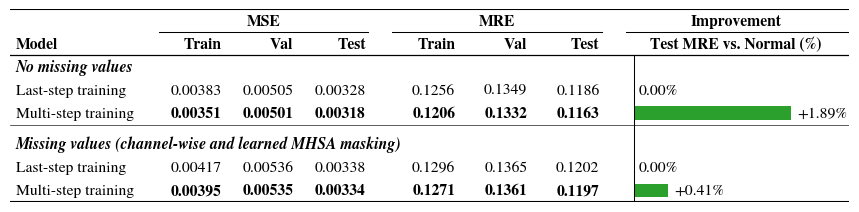

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------------------------------------------------------------------
# Stile: dimensioni reali da paper (larghezza ~ colonna doppia IEEE/Elsevier),
# font ~7.5 pt cosi' NON viene ridotto quando incluso con width=\textwidth.
# ---------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,   # font TrueType incorporati (richiesto da molte conferenze)
    "ps.fonttype": 42,
})

# =====================================================================
# DATI (MRE come frazioni)
# =====================================================================
DATA = {
    "No missing values": {
        "Normal": dict(train_mse=0.003835, val_mse=0.005052, test_mse=0.003284,
                       train_mre=0.125615, val_mre=0.134863, test_mre=0.118577),
        "Lagged": dict(train_mse=0.003509, val_mse=0.005010, test_mse=0.003182,
                       train_mre=0.120591, val_mre=0.133192, test_mre=0.116336),
    },
    "Missing values (channel-wise and learned MHSA masking)": {
        "Normal": dict(train_mse=0.004165, val_mse=0.005355, test_mse=0.003379,
                       train_mre=0.129648, val_mre=0.136465, test_mre=0.120205),
        "Lagged": dict(train_mse=0.003951, val_mse=0.005348, test_mse=0.003345,
                       train_mre=0.127063, val_mre=0.136101, test_mre=0.119715),
    },
}
BASELINE = "Normal"
LABELS = {"Normal": "Last-step training", "Lagged": "Multi-step training"}
OUT = "HYDRO_lagged_training"

MSE_SCALE, MSE_DEC = 1, 5       # MSE come nei dati originali
MRE_SCALE, MRE_DEC = 1, 4       # MRE come frazione, come nei dati originali
C_BAR = "#2ca02c"
S = 1.5                         # fattore di scala globale (dimensioni, font, spessori)
FS = 7.5 * S
GAP = 0.35                      # spazio extra sotto la linea di separazione (in unita' di riga)

KEYS = ["train_mse", "val_mse", "test_mse", "train_mre", "val_mre", "test_mre"]

# =====================================================================
# Righe
# =====================================================================
rows = []
for gi, (group, models) in enumerate(DATA.items()):
    if gi > 0:
        rows.append(("gap", None))
    rows.append(("title", group))
    base = models[BASELINE]["test_mre"]
    best = {k: min(m[k] for m in models.values()) for k in KEYS}
    for name, m in models.items():
        rows.append(("data", dict(name=name, vals=m, best=best,
                                  is_base=(name == BASELINE),
                                  impr=(base - m["test_mre"]) / base * 100)))
best_impr = max(r[1]["impr"] for r in rows if r[0] == "data")
body_h = sum(GAP if r[0] == "gap" else 1 for r in rows)

# =====================================================================
# Layout (pollici): Model | 3 MSE | gap | 3 MRE | gap | barre
# =====================================================================
nw = 0.62 * S
widths = [1.25 * S] + [nw] * 3 + [0.15 * S] + [nw] * 3 + [0.15 * S] + [1.95 * S]
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)
NUM_COLS = [1, 2, 3, 5, 6, 7]
BAR = len(widths) - 1

row_h, header_rows = 0.20 * S, 2
n_rows = body_h                      # altezza del corpo in unita' di riga
fig_h = (n_rows + header_rows) * row_h

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows, 0)
ax.axis("off")
pad = 0.05 * S


def put(col, row, text, ha="left", **kw):
    x = {"left": xs[col] + pad,
         "right": xs[col] + widths[col] - pad,
         "center": xs[col] + widths[col] / 2}[ha]
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=FS, **kw)


def span(c0, c1):  # centro di un gruppo di colonne
    return xs[c0] + (xs[c1] + widths[c1] - xs[c0]) / 2


# ---- header ----
for c0, c1, txt in [(1, 3, "MSE"), (5, 7, "MRE")]:
    ax.text(span(c0, c1), 0.5, txt, ha="center", va="center",
            fontsize=FS, fontweight="bold")
    ax.plot([xs[c0] + 0.03 * S, xs[c1] + widths[c1] - 0.03 * S], [1, 1],
            color="black", lw=0.5 * S)
ax.text(span(BAR, BAR), 0.5, "Improvement", ha="center", va="center",
        fontsize=FS, fontweight="bold")
ax.plot([xs[BAR] + 0.03 * S, total_w], [1, 1], color="black", lw=0.5 * S)

put(0, 1, "Model", fontweight="bold")
for col, n in zip(NUM_COLS, ["Train", "Val", "Test"] * 2):
    put(col, 1, n, ha="right", fontweight="bold")
ax.text(span(BAR, BAR), 1.5, "Test MRE vs. Normal (%)", ha="center",
        va="center", fontsize=FS, fontweight="bold")

# ---- scala barre ----
label_w = 0.50 * S
zero_x = xs[BAR] + 0.10 * S
scale = (widths[BAR] - 0.10 * S - label_w) / best_impr
bar_h = 0.60

# ---- corpo ----
y = header_rows
for kind, content in rows:
    if kind == "gap":
        # linea di separazione, poi spazio extra prima del titolo successivo
        ax.plot([0, total_w], [y, y], color="black", lw=0.3 * S)
        y += GAP
        continue

    if kind == "title":
        ax.text(pad, y + 0.5, content, ha="left", va="center",
                fontsize=FS, fontstyle="italic", fontweight="bold")
        y += 1
        continue

    r = content
    put(0, y, LABELS[r["name"]])
    for col, k in zip(NUM_COLS, KEYS):
        sc, dec = (MSE_SCALE, MSE_DEC) if k.endswith("mse") else (MRE_SCALE, MRE_DEC)
        put(col, y, f"{r['vals'][k] * sc:.{dec}f}", ha="right",
            fontweight="bold" if r["vals"][k] == r["best"][k] else "normal")

    if r["is_base"]:
        ax.text(zero_x + 0.04 * S, y + 0.5, "0.00%", ha="left", va="center", fontsize=FS)
    else:
        w = r["impr"] * scale
        ax.add_patch(Rectangle((zero_x, y + (1 - bar_h) / 2), w, bar_h,
                               facecolor=C_BAR, edgecolor="none"))
        ax.text(zero_x + w + 0.05 * S, y + 0.5, f"+{r['impr']:.2f}%",
                ha="left", va="center", fontsize=FS,
                fontweight="normal")
    y += 1

ax.plot([zero_x, zero_x], [header_rows, n_rows + header_rows],
        color="black", lw=0.5 * S)

# ---- regole booktabs ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.0 * S)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.6 * S)
ax.plot([0, total_w], [n_rows + header_rows] * 2, color="black", lw=1.0 * S)

# PDF vettoriale per il paper + PNG per anteprima
fig.savefig(OUT + ".png", dpi=500, bbox_inches="tight", pad_inches=0.02 * S)